# Assignment 2: Named Entities

Dataset: Named Entity Recognition (NER) Corpus from Kaggle (ner.csv)

In [13]:
%pip install spacy scikit-learn pandas matplotlib
!python -m spacy download en_core_web_sm

Note: you may need to restart the kernel to use updated packages.
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---- ----------------------------------- 1.3/12.8 MB 8.1 MB/s eta 0:00:02
     ---------- ----------------------------- 3.4/12.8 MB 9.4 MB/s eta 0:00:02
     ------------------ --------------------- 5.8/12.8 MB 10.2 MB/s eta 0:00:01
     ------------------------- -------------- 8.1/12.8 MB 10.6 MB/s eta 0:00:01
     ------------------------------- ------- 10.5/12.8 MB 10.8 MB/s eta 0:00:01
     --------------------------------------  12.6/12.8 MB 11.0 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 10.5 MB/s  0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [14]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import spacy
from spacy import displacy
from spacy.tokens import Doc
from sklearn.metrics import classification_report, f1_score

In [15]:
# load data, one sentence per row
df = pd.read_csv("ner.csv")
df.head()

,Sentence #,Sentence,POS,Tag
0,Sentence: 1,Thousands of demonstrators have marched throug...,"['NNS', 'IN', 'NNS', 'VBP', 'VBN', 'IN', 'NNP'...","['O', 'O', 'O', 'O', 'O', 'O', 'B-geo', 'O', '..."
1,Sentence: 2,Families of soldiers killed in the conflict jo...,"['NNS', 'IN', 'NNS', 'VBN', 'IN', 'DT', 'NN', ...","['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', ..."
2,Sentence: 3,They marched from the Houses of Parliament to ...,"['PRP', 'VBD', 'IN', 'DT', 'NNS', 'IN', 'NN', ...","['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', ..."
3,Sentence: 4,"Police put the number of marchers at 10,000 wh...","['NNS', 'VBD', 'DT', 'NN', 'IN', 'NNS', 'IN', ...","['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', ..."
4,Sentence: 5,The protest comes on the eve of the annual con...,"['DT', 'NN', 'VBZ', 'IN', 'DT', 'NN', 'IN', 'D...","['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', ..."


In [16]:
sentences = df.copy()

# sentence string -> list of words (split(" ") keeps words and tags aligned)
sentences["words"] = sentences["Sentence"].str.split(" ")

# tag string -> real list
sentences["tags"] = sentences["Tag"].apply(ast.literal_eval)

# check: 47959 sentences, and 0 = every sentence has one tag per word
# (if not 0, words and tags get paired wrong later in zip)
print(len(sentences))
print((sentences["words"].str.len() != sentences["tags"].str.len()).sum())

47959
0


In [17]:
nlp = spacy.load("en_core_web_sm")

# use the dataset's words so spaCy tokens match the tags
def run_spacy(words):
    doc = Doc(nlp.vocab, words=words)
    return nlp(doc)

# first 100 sentences (used in tasks 2-4)
docs = [run_spacy(w) for w in sentences["words"].head(100)]

In [18]:
# task 2: show entities of first 5 sentences
for doc in docs[:5]:
    displacy.render(doc, style="ent", jupyter=True)

In [19]:
# task 3: count predicted entity types
counts = Counter(ent.label_ for doc in docs for ent in doc.ents)
freq = pd.Series(counts).sort_values()
print(freq.sort_values(ascending=False))

GPE            75
DATE           49
ORG            45
NORP           45
CARDINAL       28
PERSON         23
LOC             3
LAW             1
ORDINAL         1
WORK_OF_ART     1
FAC             1
LANGUAGE        1
QUANTITY        1
dtype: int64


Entity types are categories without an order, and I want to compare how often each one appears, so I use a bar chart.
A pie chart would be hard to read with 13 types where many appear only once.

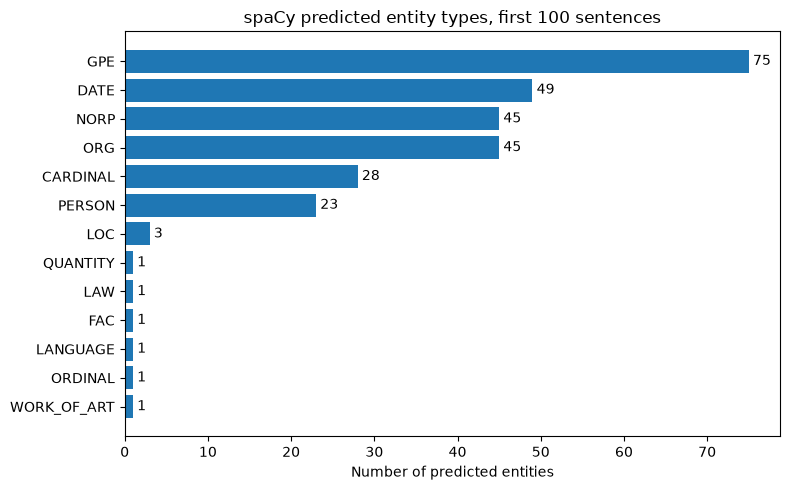

In [20]:
# bar chart: entity types are categories, we compare their counts
# horizontal so long labels (e.g. WORK_OF_ART) fit
# sorted in cell 7, so the most common type is at the top
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(freq.index, freq.values)
ax.bar_label(bars, padding=3)  # show the count next to each bar
ax.set_xlabel("Number of predicted entities")
ax.set_title("spaCy predicted entity types, first 100 sentences")
plt.tight_layout()
plt.show()

## 4. How good is spaCy compared to the ground truth?

The dataset and spaCy use different label names, so I map both to three shared classes:

| Class | Dataset | spaCy |
|---|---|---|
| LOC | geo, gpe | GPE, LOC |
| PER | per | PERSON |
| ORG | org | ORG |

Everything else counts as O (not an entity). I also remove the B- and I- from the dataset tags.

As the metric I use the F1-score. Accuracy wouldn't make sense here because most words are O,
so even a model that finds no entities at all would get a high accuracy.
F1 combines precision (how many of spaCy's entities are correct) and recall (how many of the real entities spaCy found).
I leave O out of the average so it doesn't make the score look better than it is.

In [21]:
# task 4: map both label sets to LOC, PER, ORG
DATASET_MAP = {"geo": "LOC", "gpe": "LOC", "per": "PER", "org": "ORG"}
SPACY_MAP   = {"GPE": "LOC", "LOC": "LOC", "PERSON": "PER", "ORG": "ORG"}
LABELS = ["LOC", "PER", "ORG"]

# "B-geo" -> "LOC", everything else -> "O"
def map_gold(tag):
    if tag == "O":
        return "O"
    return DATASET_MAP.get(tag.split("-", 1)[1], "O")

In [22]:
# true labels vs spaCy labels, word by word
y_true, y_pred = [], []
for doc, tags in zip(docs, sentences["tags"].head(100)):
    for token, tag in zip(doc, tags):
        y_true.append(map_gold(tag))
        y_pred.append(SPACY_MAP.get(token.ent_type_, "O"))

# both should be the same length
print(len(y_true), len(y_pred))

2307 2307


In [23]:
# F1 per class, O left out
print(classification_report(y_true, y_pred, labels=LABELS, digits=3, zero_division=0))

# average F1 over the 3 classes
print("Macro F1:", round(f1_score(y_true, y_pred, labels=LABELS, average="macro"), 3))

              precision    recall  f1-score   support

         LOC      0.911     0.631     0.745       130
         PER      0.750     0.635     0.688        52
         ORG      0.717     0.740     0.728        96

   micro avg      0.798     0.669     0.728       278
   macro avg      0.793     0.668     0.720       278
weighted avg      0.814     0.669     0.729       278

Macro F1: 0.72


In [24]:
# which gpe words did spaCy miss?
misses = Counter()
for doc, tags in zip(docs, sentences["tags"].head(100)):
    for token, tag in zip(doc, tags):
        if tag.endswith("gpe") and token.ent_type_ != "GPE":
            misses[(token.text, token.ent_type_)] += 1

misses.most_common(10)

[(('Pakistani', 'NORP'), 5),
 (('British', 'NORP'), 3),
 (('Sudanese', 'NORP'), 3),
 (('Indonesian', 'NORP'), 3),
 (('Iranian', 'NORP'), 2),
 (('German', 'NORP'), 2),
 (('American', 'NORP'), 2),
 (('English', 'LANGUAGE'), 1),
 (('European', 'NORP'), 1),
 (('Germans', 'NORP'), 1)]